# Longitud real del pez en cm (homografía con ArUco)

Continúa `fish_skeleton_poly.ipynb` (se conservan sus funciones). Para cada pez:
1. Se calcula la homografía `H` que lleva las 4 esquinas del ArUco (píxeles) a un plano métrico (cm), con el marcador de `TAMANO_ARUCO_CM` de lado.
2. Los puntos que discretizan el polinomio de grado 4 (entre extremos) se proyectan con `cv2.perspectiveTransform` a cm.
3. Se suman las distancias euclídeas entre puntos consecutivos -> `longitud_pez_cm`.

In [48]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from ultralytics import YOLO

WEIGHTS = Path(r"C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolov8n-seg_merged\weights\best.pt")
CONF = 0.3
IMGSZ = 640
SKELETON_COLOR = (0, 255, 255)     # RGB, cian
BORDER_COLOR = (255, 0, 255)     # RGB, rojo
ARUCO_COLOR = (0, 155, 0)        # RGB, verde
ARUCO_DICT = cv2.aruco.DICT_4X4_1000   # incluye los IDs de 4X4_50/100/250

model = YOLO(WEIGHTS)

HULL_COLOR = (255, 165, 0)        # RGB, naranja (convex hull)
FIT_COLOR = (0, 0, 255)          # RGB, azul (polinomio ajustado, todo el rango de la máscara)
POLY_COLOR = (255, 0, 0)         # RGB, rojo (polinomio entre extremos)
ENDS_COLOR = (255, 255, 0)       # RGB, amarillo (extremos cabeza/cola)


## Función: máscaras + esqueletización

In [49]:
KERNEL_3x3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
KERNEL_CROSS = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))


def skeletonize(mask):
    """Esqueleto morfológico (Lantuéjoul) con erosiones/aperturas de cv2. mask: uint8 {0,255}."""
    img = mask.copy()
    skel = np.zeros_like(img)
    while cv2.countNonZero(img) > 0:
        eroded = cv2.erode(img, KERNEL_CROSS)
        opened = cv2.dilate(eroded, KERNEL_CROSS)
        skel = cv2.bitwise_or(skel, cv2.subtract(img, opened))
        img = eroded
    return skel


def border(mask):
    """Píxeles de la máscara que no están rodeados por sus 8 vecinos."""
    return cv2.subtract(mask, cv2.erode(mask, KERNEL_3x3, borderType=cv2.BORDER_CONSTANT, borderValue=0))


def fish_skeletons(img_bgr):
    """Predice máscaras de instancia y devuelve (masks, skeletons, borders, confs).
    masks/skeletons/borders: listas de arrays uint8 {0,255}; confs: confianza del modelo por pez."""
    h, w = img_bgr.shape[:2]
    res = model.predict(img_bgr, imgsz=IMGSZ, conf=CONF, retina_masks=True, verbose=False)[0]
    masks, skeletons, borders = [], [], []
    if res.masks is None:
        return masks, skeletons, borders, []
    confs = res.boxes.conf.cpu().numpy().tolist()
    for m in res.masks.data.cpu().numpy():
        m = (m > 0.5).astype(np.uint8) * 255
        if m.shape != (h, w):
            m = cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)
        masks.append(m)
        skeletons.append(skeletonize(m))
        borders.append(border(m))
    return masks, skeletons, borders, confs


ARUCO_DETECTOR = cv2.aruco.ArucoDetector(
    cv2.aruco.getPredefinedDictionary(ARUCO_DICT), cv2.aruco.DetectorParameters()
)


def detect_aruco(img_bgr):
    """Busca marcadores ArUco 4x4. Devuelve (corners, ids); corners: lista de arrays (4, 2) float32."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    corners, ids, _ = ARUCO_DETECTOR.detectMarkers(gray)
    if ids is None:
        return [], []
    return [c.reshape(4, 2) for c in corners], ids.flatten().tolist()


def plot_skeletons(img_bgr, skeletons, borders, confs=(), aruco_corners=(), aruco_ids=(), name_file_output="defecto.png"):
    out = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    for b in borders:
        out[b > 0] = BORDER_COLOR
    for s in skeletons:
        out[s > 0] = SKELETON_COLOR
    thickness = max(2, round(max(out.shape[:2]) / 400))
    font_scale = thickness / 3
    for b, conf in zip(borders, confs):
        ys, xs = np.nonzero(b)
        if len(ys) == 0:
            continue
        txt = f"{conf:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        x = int(np.clip((xs.min() + xs.max()) / 2 - tw / 2, 0, out.shape[1] - tw))
        y = int(max(ys.min() - 2 * thickness, th))   # justo arriba del pez, sin salirse de la imagen
        cv2.putText(out, txt, (x, y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, BORDER_COLOR, thickness)
    for c, i in zip(aruco_corners, aruco_ids):
        cv2.polylines(out, [c.astype(np.int32)], isClosed=True, color=ARUCO_COLOR, thickness=thickness)
        x, y = c[0].astype(int)
        cv2.putText(out, f"id {i}", (x, y - 2 * thickness), cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale, ARUCO_COLOR, thickness)
    plt.figure(figsize=(12, 8))
    plt.imshow(out)
    aruco_txt = f"ArUco {list(aruco_ids)}" if len(aruco_ids) else "sin ArUco"
    plt.title(f"{len(skeletons)} peces | borde + esqueleto | {aruco_txt}")
    plt.axis("off")

    output_name = name_file_output
    plt.savefig(output_name, bbox_inches='tight', dpi=300)
    print(f"Imagen guardada como: {output_name}")


    plt.show()

In [50]:
POLY_DEG = 4
N_SAMPLES = 2000


def fit_centerline(skel, mask, deg=POLY_DEG):
    """Ajusta un polinomio de grado `deg` a los puntos del esqueleto.
    Para que funcione con peces en cualquier orientación (incluso verticales) el ajuste se hace en el sistema
    de ejes principales del esqueleto (PCA): s = a t^4 + b t^3 + c t^2 + d t + e, con t sobre el eje mayor.
    Devuelve (curve, frame): curve(t) -> puntos (N, 2) en la imagen; frame = (centro, u, tmin, tmax) con
    tmin/tmax el rango de la MÁSCARA sobre el eje mayor."""
    ys, xs = np.nonzero(skel)
    pts = np.column_stack([xs, ys]).astype(np.float64)
    c = pts.mean(0)
    _, _, vt = np.linalg.svd(pts - c, full_matrices=False)
    u, v = vt[0], vt[1]
    t = (pts - c) @ u
    s = (pts - c) @ v
    scale = np.abs(t).max() or 1.0
    coef = np.polyfit(t / scale, s, deg)          # normalizado por condicionamiento numérico

    my, mx = np.nonzero(mask)
    mt = (np.column_stack([mx, my]) - c) @ u

    def curve(tt):
        tt = np.asarray(tt, dtype=np.float64)
        return c + np.outer(tt, u) + np.outer(np.polyval(coef, tt / scale), v)

    return curve, (c, u, mt.min(), mt.max())


def curve_hull_ends(curve, frame, hull, margin=0.3):
    """Extremos de la curva: puntos donde el polinomio, prolongado desde el centro hacia cada lado, sale del convex hull
    (interpolando sobre el segmento que cruza el borde)."""
    _, _, tmin, tmax = frame
    L = tmax - tmin
    ts = np.linspace(tmin - margin * L, tmax + margin * L, N_SAMPLES)
    pts = curve(ts)
    inside = np.array([cv2.pointPolygonTest(hull, (float(x), float(y)), False) >= 0 for x, y in pts])
    i0 = int(np.argmin(np.abs(ts - (tmin + tmax) / 2)))      # muestra más cercana al centro de la máscara
    if not inside[i0]:
        i0 = int(np.argmax(inside))
    ends = []
    for direction in (-1, 1):
        i = i0
        while 0 <= i + direction < len(ts) and inside[i + direction]:
            i += direction
        j = min(max(i + direction, 0), len(ts) - 1)
        lo, hi = ts[i], ts[j]                                 # lo adentro, hi afuera -> bisección
        for _ in range(30):
            mid = (lo + hi) / 2
            x, y = curve([mid])[0]
            if cv2.pointPolygonTest(hull, (float(x), float(y)), False) >= 0:
                lo = mid
            else:
                hi = mid
        ends.append(lo)
    t_a, t_b = ends
    return t_a, t_b


def analyze_fish(mask):
    """Esqueleto morfológico -> polinomio grado 4 -> extremos con convex hull. Devuelve dict con los resultados de un pez."""
    skel = skeletonize(mask)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(contour)
    curve, frame = fit_centerline(skel, mask)
    t_a, t_b = curve_hull_ends(curve, frame, hull)
    line = curve(np.linspace(t_a, t_b, 200))
    fit = curve(np.linspace(frame[2], frame[3], 200))      # polinomio ajustado sobre todo el rango de la máscara
    length = float(np.sum(np.linalg.norm(np.diff(line, axis=0), axis=1)))
    return dict(skeleton=skel, fit=fit, contour=contour, hull=hull, line=line,
                end_a=line[0], end_b=line[-1], length_px=length)


## Homografía y longitud en cm

In [51]:
TAMANO_ARUCO_CM = 5.0   # lado real del marcador ArUco (cm)

# Esquinas del ArUco en el plano real (cm), mismo orden que OpenCV: sup-izq, sup-der, inf-der, inf-izq
ARUCO_CM = np.array([(0, 0), (TAMANO_ARUCO_CM, 0), (TAMANO_ARUCO_CM, TAMANO_ARUCO_CM), (0, TAMANO_ARUCO_CM)],
                    dtype=np.float32)


def homography_px_to_cm(aruco_corners_px):
    """Homografía H (3x3) de píxeles a cm a partir de las 4 esquinas del ArUco detectado (array (4, 2))."""
    src = np.asarray(aruco_corners_px, dtype=np.float32).reshape(4, 2)
    H, _ = cv2.findHomography(src, ARUCO_CM)
    if H is None:
        raise ValueError("No se pudo calcular la homografía con las esquinas del ArUco")
    return H


def longitud_pez_cm(curve_px, H):
    """Longitud (cm) de la curva discretizada `curve_px` (N, 2) en píxeles:
    proyecta los puntos con H y suma las distancias entre puntos consecutivos."""
    pts = np.asarray(curve_px, dtype=np.float32).reshape(-1, 1, 2)    # perspectiveTransform exige (N, 1, 2) float32
    pts_cm = cv2.perspectiveTransform(pts, np.asarray(H, dtype=np.float64)).reshape(-1, 2)
    return float(np.sum(np.linalg.norm(np.diff(pts_cm, axis=0), axis=1)))

In [52]:
def plot_length_cm(img_bgr, results, confs, aruco_corners, aruco_ids, name_file_output="result_length_cm.png"):
    """Dibuja (para auditoría) esqueleto, convex hull, contorno, polinomio, extremos, confianza y largo en cm de cada pez, y el tamaño del ArUco."""
    out = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    thickness = max(2, round(max(out.shape[:2]) / 400))
    font_scale = thickness / 3
    for r, conf in zip(results, confs):
        out[r["skeleton"] > 0] = SKELETON_COLOR
        cv2.polylines(out, [r["contour"]], True, BORDER_COLOR, max(1, thickness // 2))
        cv2.polylines(out, [r["hull"]], True, HULL_COLOR, max(1, thickness // 2))
        cv2.polylines(out, [np.round(r["line"]).astype(np.int32).reshape(-1, 1, 2)], False, POLY_COLOR, thickness)
        for p in (r["end_a"], r["end_b"]):
            cv2.circle(out, tuple(np.round(p).astype(int)), 3 * thickness, ENDS_COLOR, -1)
        x, y, w, _ = cv2.boundingRect(r["contour"])
        txt = f"{conf:.2f} | {r['length_cm']:.2f} cm"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        x = int(np.clip(x + w / 2 - tw / 2, 0, out.shape[1] - tw))
        cv2.putText(out, txt, (x, int(max(y - 2 * thickness, th))), cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale, BORDER_COLOR, thickness)
    for c, i in zip(aruco_corners, aruco_ids):
        cv2.polylines(out, [c.astype(np.int32)], isClosed=True, color=ARUCO_COLOR, thickness=thickness)
        txt = f"{TAMANO_ARUCO_CM:g} cm"       # medida real (hardcodeada) del lado del ArUco
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        cx, cy = c.mean(0)
        cv2.putText(out, txt, (int(cx - tw / 2), int(cy + th / 2)), cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale, (255, 255, 255), thickness)
    plt.figure(figsize=(12, 8))
    plt.imshow(out)
    plt.title(f"{len(results)} peces | largo en cm (ArUco {TAMANO_ARUCO_CM:g} cm)")
    plt.axis("off")
    plt.savefig(name_file_output, bbox_inches="tight", dpi=300)
    print(f"Imagen guardada como: {name_file_output}")
    plt.show()

## Imagen particular

In [53]:
IMAGE_PATH = Path(r"C:/Users/juanm/Documents/GitHub/fish_cv_pfc/example_2.jpg")

img = cv2.imread(str(IMAGE_PATH))
assert img is not None, f"No se pudo leer {IMAGE_PATH}"
masks, _, _, confs = fish_skeletons(img)
results = [analyze_fish(m) for m in masks]
aruco_corners, aruco_ids = detect_aruco(img)
assert len(aruco_corners) > 0, "No se detectó ningún ArUco: no se puede calibrar la escala"

H = homography_px_to_cm(aruco_corners[0])      # se usa el primer ArUco detectado
for k, r in enumerate(results):
    r["length_cm"] = longitud_pez_cm(r["line"], H)
    print(f"pez {k}: largo = {r['length_cm']:.2f} cm ({r['length_px']:.1f} px)")

# Control: el propio ArUco proyectado debe medir TAMANO_ARUCO_CM por lado
c = aruco_corners[0].astype(np.float32).reshape(-1, 1, 2)
c_cm = cv2.perspectiveTransform(c, H).reshape(-1, 2)
print("lados ArUco (cm):", np.linalg.norm(c_cm - np.roll(c_cm, -1, axis=0), axis=1).round(3))

pez 0: largo = 31.05 cm (508.9 px)
pez 1: largo = 27.01 cm (441.9 px)
lados ArUco (cm): [          5           5           5           5]


In [54]:
IMAGE_PATH = Path(r"C:/Users/juanm/Documents/GitHub/fish_cv_pfc/example_1.jpg")

img2 = cv2.imread(str(IMAGE_PATH))
assert img2 is not None, f"No se pudo leer {IMAGE_PATH}"
masks2, _, _, confs2 = fish_skeletons(img2)
results2 = [analyze_fish(m) for m in masks2]
aruco_corners2, aruco_ids2 = detect_aruco(img2)
assert len(aruco_corners2) > 0, "No se detectó ningún ArUco: no se puede calibrar la escala"

H = homography_px_to_cm(aruco_corners2[0])      # se usa el primer ArUco detectado
for k, r in enumerate(results2):
    r["length_cm"] = longitud_pez_cm(r["line"], H)
    print(f"pez {k}: largo = {r['length_cm']:.2f} cm ({r['length_px']:.1f} px)")

# Control: el propio ArUco proyectado debe medir TAMANO_ARUCO_CM por lado
c = aruco_corners2[0].astype(np.float32).reshape(-1, 1, 2)
c_cm = cv2.perspectiveTransform(c, H).reshape(-1, 2)
print("lados ArUco (cm):", np.linalg.norm(c_cm - np.roll(c_cm, -1, axis=0), axis=1).round(3))

pez 0: largo = 28.20 cm (408.0 px)
pez 1: largo = 21.76 cm (318.3 px)
pez 2: largo = 21.18 cm (317.7 px)
pez 3: largo = 14.56 cm (217.0 px)
lados ArUco (cm): [          5           5           5           5]


## Resultados

Imagen guardada como: result_length_cm.png


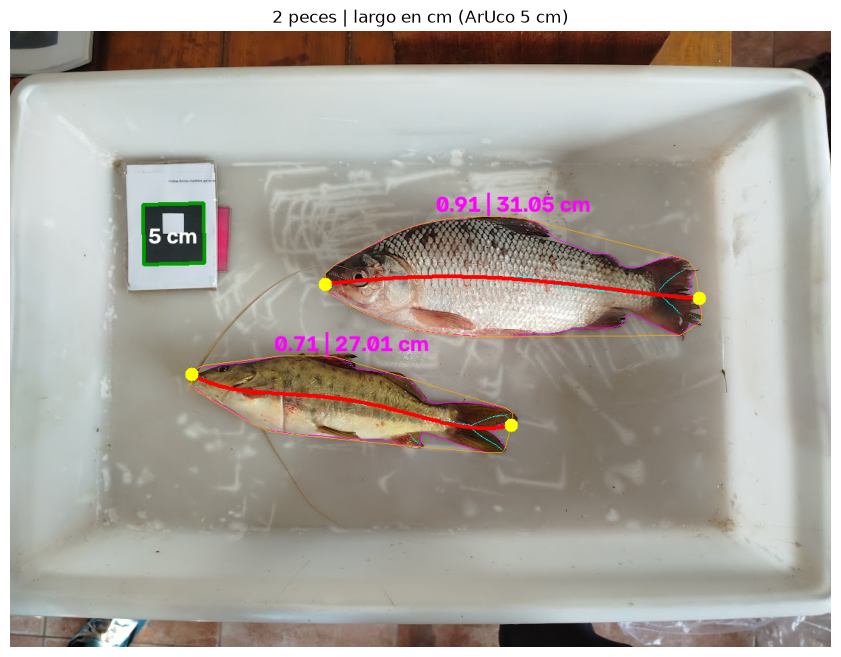

Imagen guardada como: result_length_cm.png


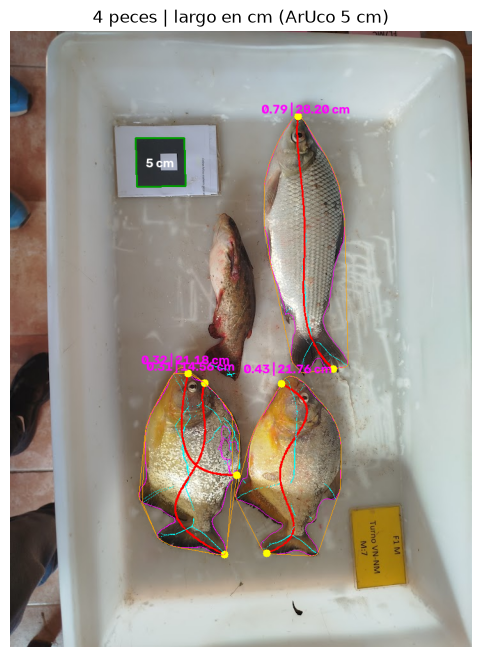

In [55]:
plot_length_cm(img, results, confs, aruco_corners, aruco_ids)
plot_length_cm(img2, results2, confs2, aruco_corners2, aruco_ids2)
